# Zenteno reducido a S · Kie0 fijo frente a libre y diagnóstico 16
Recalibración sólo LAB004–009 de mu0,betaS0,Ks0,Yxn,Yes, con Kie0 fijo al16 (96.26516563486751g/L a20C), conservando su ley térmica. Referencia anterior S/Kie libre congelada desde la ejecución previa; no se vuelve a seleccionar con ensayos reservados.
Mismos datos depurados, tratamientos YAN, peso reducido biomasa, correcciones X0, pulsos instantáneos, Kn/Kd0, mantenimiento, Yxs y leyes térmicas. kLa=.07467887635557982 y ganancia=.635238911849421 fijos. LAB019–021 y LAB016–018 para comparación reservada de esta recalibración; 019–021 participaron históricamente del ajuste del gas.
S0=G0+F0; S de entrenamiento sólo si ambos análisis están disponibles en la misma muestra. sigmaS por propagación independiente de errores G/F. Dos inicios deterministas; cotas exploratorias Ks0[.1,200], betaS0[.1,20], restantes heredadas. No se afirma óptimo global. Comparaciones de RMSE sobre muestras comunes, no costes entre estructuras diferentes.


## Ecuaciones y alcance
\[
\mu=\mu_0a_\mu(T)\frac{N}{N+K_N(T)},\qquad
\beta_S=\beta_{S0}a_\beta(T)\frac{S}{S+K_S(T)}\frac{K_{iE}(T)}{E+K_{iE}(T)}.
\]
\[
\dot X=(\mu-k_d)X,\quad \dot N=-\mu X/Y_{X/N},\quad
\dot S=-X[\mu/Y_{X/S}+\beta_S/Y_{E/S}+m(T)S/(S+1)],\quad \dot E=\beta_SX.
\]
Concentraciones en g/L, tiempo en horas; el 1 del factor de mantenimiento es 1 g/L, igual al módulo original. Se anula mu si S está agotado. Nutrición: salto instantáneo de N, muestra previa al salto si coincide.
\[
qprod=(\mu/12.72+\beta_S/1.05)X,\quad
\dot C_d=\min(A\,qprod,k_La\max(C_{sat}-C_d,0)),\quad
q_{gas}=A\,qprod-\dot C_d,\quad q_{pred}=g\,q_{gas}.
\]
A usa la misma transición suave 5–10 g/L de azúcar consumido que el 16. La mortalidad conserva exactamente su umbral y ley térmica/etanol. K_N y K_S conservan la ley térmica correspondiente del original.

## Comparaciones y alcance
Tres trayectorias: 16 original, S con Kie0 libre de la ejecución anterior (congelado), y S con Kie0 fijo al16 (nuevo ajuste). La referencia libre quedó en Kie0=999.989g/L, cerca de cota1000; se conserva como resultado histórico, no valor fisiológico validado.
La química reservada mantiene el soporte del lector del16 (incluye NUT y total GF disponible). Densidad sólo como contraste gráfico; no se ajusta con ella. Se excluyen iniciales de las métricas. Tiempos de agotamiento aproximados sobre malla de salida. Las diferencias con16 incluyen tanto reducción G/F como cambio de objetivo de ajuste a S.


In [1]:
from pathlib import Path
from dataclasses import replace
import sys,json,hashlib,math,time
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares,minimize_scalar
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.data import natural_batches
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
NAME='17_zenteno_single_sugar'
protected=[p for folder in ['src','configs','data/compatibility/chemistry','data/cleaned/natural/lab004_009','notebooks'] for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and not p.name.startswith(NAME+'.')]
hashes={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
data,training,profiles=natural_batches(ROOT)
# Correcciones de recuento inicial indicadas por el usuario; originales conservados.
INITIAL_VIABLE_MCELLS_ML={'LAB004':10.75,'LAB005':11.25}
initial_biomass_audit=[];corrected_training=[]
for batch in training:
 if batch.batch in INITIAL_VIABLE_MCELLS_ML:
  count=INITIAL_VIABLE_MCELLS_ML[batch.batch];x0=count*.03
  ids=np.flatnonzero(np.isclose(batch.time,0.));assert len(ids)==1
  obs0={k:v.copy() for k,v in batch.observations.items()};obs0['X'][ids[0]]=x0
  initial_biomass_audit.append(dict(LAB=batch.batch,original_g_L=batch.initials['X'],viables_millones_mL=count,corregido_g_L=x0))
  batch=replace(batch,initials={**batch.initials,'X':x0},observations=obs0)
  mask=data.batch.eq(batch.batch)&np.isclose(data.time_h,0.)
  assert mask.sum()==1
  data.loc[mask,'X_viable_kg_m3']=x0;data.loc[mask,'X_viable_mcells_ml']=count
  assert batch.initials['X']==batch.observations['X'][ids[0]]
 corrected_training.append(batch)
training=corrected_training
assert len(initial_biomass_audit)==2
display(pd.DataFrame(initial_biomass_audit))

start=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
config=json.loads((ROOT/'configs/models/without_transporters/calibration.json').read_text())
# Tabla 2 de Zenteno: Kn=0.01 g/L a23C; nuestro Kn0 se referencia a20C.
KN_ZENTENO_G_L=0.01;KN_PAPER_REF_K=296.15;KN_CODE_REF_K=293.15
KN_THERMAL_FACTOR=np.exp(kin.FIXED_CONSTANTS['EaKn']*(KN_PAPER_REF_K-KN_CODE_REF_K)/(KN_CODE_REF_K*kin.FIXED_CONSTANTS['R']*KN_PAPER_REF_K))
start['Kn0']=KN_ZENTENO_G_L/KN_THERMAL_FACTOR
KD0_ZENTENO_H=0.00044
start['Kd0']=KD0_ZENTENO_H
assert np.isclose(start['Kn0']*KN_THERMAL_FACTOR,KN_ZENTENO_G_L,rtol=1e-14)
display(pd.Series(dict(Kn_Zenteno_g_L=KN_ZENTENO_G_L,referencia_paper_C=23,Kn0_codigo_g_L=start['Kn0'],referencia_codigo_C=20),name='Kn fijo y conversión de referencia térmica'))
names=[k for k in config['bounds'] if k not in ['aN','KNa','Kn0','Kd0']]
assert len(names)==8 and 'Kn0' not in names and 'Kd0' not in names
bounds={k:config['bounds'][k] for k in names};lo,hi=np.array(list(bounds.values())).T
fixed={k:v for k,v in start.items() if k not in names}
display(pd.Series(fixed,name='Fijos: theta_full salvo Kn y Kd0 de Zenteno'))
display(pd.DataFrame([dict(parametro=k,inicio=start[k],inicio_factible=np.clip(start[k],lo[i]+1e-10,hi[i]-1e-10),minimo=lo[i],maximo=hi[i]) for i,k in enumerate(names)]))


diffs=[]
bylab={b.batch:b for b in training}
for a,b in [('LAB004','LAB005'),('LAB007','LAB008')]:
 aa=pd.Series(bylab[a].observations['X'],index=bylab[a].time);bb=pd.Series(bylab[b].observations['X'],index=bylab[b].time)
 z=pd.concat([aa,bb],axis=1).dropna();diffs.extend((z.iloc[:,0]-z.iloc[:,1]).tolist())
sigma_rep=float(np.sqrt(np.mean(np.square(diffs)))/np.sqrt(2));SIGMA_X=max(.5,3*sigma_rep)
assert len(diffs)>0
print('Pares de réplicas:',len(diffs),'sigma réplica:',sigma_rep,'sigmaX aplicada:',SIGMA_X)
treated=[];audit=[];rules=[]
for b in training:
 obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
 obs['N'][np.isfinite(old)&(old<=.020)]=0
 if b.batch=='LAB006':
  ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
  obs['N'][ids]=0;depletion=122.
 else:
  last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
  depletion=float(b.time[ids[0]])
 obs['N'][b.time>depletion+12]=np.nan
 for i in np.flatnonzero(np.isfinite(old)):
  audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
 assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
 treated.append(replace(b,observations=obs))
 rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
def sigma(state,y):return np.full_like(y,SIGMA_X) if state=='X' else kin.sigma_for_state(state,y)
def simulate(b,p):
 def rhs(t,y):
  out=np.asarray(kin.rhs(t,y,p,b))
  if y[2]<=0 or y[3]<=0:
   q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
   out[0]-=growth;out[1]+=growth/p['Yxn'];out[2]+=growth/p['Yxg'];out[3]+=growth/p['Yxf']
  return out
 # Muestra previa al salto si coincide con la nutrición; dosis completa después.
 minimum=np.full(5,np.inf);jumps=[];events={}
 for tp,dose in b.pulses.get('N',()):
  assert tp>float(b.time[0]) and dose>=0,'No se admiten pulsos iniciales extra'
  if tp<=b.time[-1]:events[float(tp)]=events.get(float(tp),0.)+float(dose)
 times=np.asarray(b.time);state=kin.initial_vector(b);records={float(times[0]):state.copy()};now=float(times[0])
 for end in sorted(set([float(times[-1])]+list(events))):
  requested=times[(times>now)&(times<=end)]
  sol=solve_ivp(rhs,(now,end),state,t_eval=np.unique(np.r_[requested,end]),method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
  if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-4,1e-6])):raise RuntimeError('Integración química inválida '+b.batch+' '+str(sol.message)+' mínimos='+str(dict(zip(kin.STATE_NAMES,sol.y.min(axis=1)))))
  minimum=np.minimum(minimum,sol.y.min(axis=1))
  records.update({float(t):y.copy() for t,y in zip(sol.t,sol.y.T)});state=sol.y[:,-1].copy();now=end
  if end in events:
   before=state.copy();state[1]+=events[end]
   assert np.isclose(state[1]-before[1],events[end],atol=1e-12) and np.array_equal(state[[0,2,3,4]],before[[0,2,3,4]])
   jumps.append(dict(t=end,dose=events[end],before=before.copy(),after=state.copy()))
 f=pd.DataFrame(np.maximum(np.vstack([records[float(t)] for t in times]),0),index=times,columns=kin.STATE_NAMES);f['GF']=f.G+f.F
 f.attrs['minimum_integrated_states']=dict(zip(kin.STATE_NAMES,minimum.tolist()))
 f.attrs['pulse_jumps']=jumps
 assert np.isclose(sum(j['dose'] for j in jumps),sum(events.values()),atol=1e-12)
 return f

def with_jumps(f):
 extra=[];tt=[]
 for j in f.attrs['pulse_jumps']:
  if j['t'] not in f.index:extra.append(j['before']);tt.append(j['t'])
  extra.append(j['after']);tt.append(j['t'])
 if not extra:return f
 added=pd.DataFrame(extra,index=tt,columns=kin.STATE_NAMES);added['GF']=added.G+added.F
 return pd.concat([f,added]).sort_index(kind='stable')

support=[(b,s,np.isfinite(b.observations[s])&(b.time>0)) for b in treated for s in kin.STATE_NAMES]
NR=sum(m.sum() for b,s,m in support);calls=0;rejected=0


# Química congelada de la recalibración anterior; sin optimización en esta prueba.
theta={'mu0': 0.09403147367985473, 'betaG0': 0.42243676903335664, 'betaF0': 0.6236552480900203, 'Kn0': 0.008257860224319971, 'Kg0': 4.400775419123265, 'Kf0': 19.296083508118652, 'Kig0': 65.01993873457147, 'Kie0': 96.26516563486751, 'Kd0': 0.00044, 'Yxn': 6.456225797038313, 'Yxg': 0.9660935553477866, 'Yxf': 1.1098958529485594, 'Yeg': 0.4684585383875136, 'Yef': 0.5113278649826252, 'm0': 0.0183385793928771}
assert theta['Kn0']==start['Kn0'] and theta['Kd0']==KD0_ZENTENO_H
assert all(theta[k]==v for k,v in fixed.items())
print('PARÁMETROS QUÍMICOS COMPLETOS',json.dumps(theta,indent=2))
print('Química fija: no se recalibra en esta prueba de activación.')
traincurves={b.batch:simulate(b,theta) for b in treated}


v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLD=LABS[3:]
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h']);obs=observations(raw)
batches={};cores={};volumes={};caches={};activation={};entry=[]
for lab in LABS:
 b=v.batches[lab];ev=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h');et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
 def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
 volumes[lab]=volume
 if lab in TRAIN:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
 if lab=='LAB017':b=replace(b,pulses={**b.pulses,'N':((min(t for t,d in b.pulses['N']),sum(d for t,d in b.pulses['N'])),)})
 if lab=='LAB021':b=replace(b,initials={**b.initials,'X':9.*.03})
 batches[lab]=b;f=simulate(b,theta);cores[lab]=f;f=with_jumps(f)
 tt=np.unique(np.r_[np.arange(0,float(f.index[-1]),.1),f.index[-1]])
 rates=[]
 for t in tt:
  y=[np.interp(t,f.index,f[s]) for s in kin.STATE_NAMES];q=kin.kinetic_terms(theta,kin.temperature_at(b,t),*y)
  if y[2]<=0 or y[3]<=0:q['mu']=0.
  rates.append((q['mu']/12.72+(q['beta_g']+q['beta_f'])/1.05)*y[0])
 caches[lab]=(tt,np.asarray(rates))
 consumed=b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.GF)
 z=np.clip((consumed-5.)/5.,0.,1.);activation[lab]=z*z*(3.-2.*z)
 assert np.all(activation[lab][consumed<=5.]==0) and np.all(activation[lab][consumed>=10.]==1)
 entry.append(dict(LAB=lab,**b.initials,pulsos=b.pulses['N'],corte_h=v.horizons[lab]))
 obs[lab]=obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy()
display(pd.DataFrame(entry))
CSAT=1.5
def gas(lab,k,gain=1,activated=True):
 t,source=caches[lab]
 if activated:source=source*activation[lab]
 cd=np.zeros(len(t));qout=np.zeros(len(t));acc=np.zeros(len(t));qout[0]=max(source[0]-k*CSAT,0)
 for i,dt in enumerate(np.diff(t),1):
  qp=(source[i-1]+source[i])/2;D=max(CSAT-cd[i-1],0)
  if qp<=0 or D<=0:delta=0.
  elif k*D<=qp:delta=D*(-np.expm1(-k*dt))
  else:
   crossing=(D-qp/k)/qp;linear=min(dt,crossing);delta=qp*linear
   if crossing<dt:delta+=(qp/k)*(-np.expm1(-k*(dt-crossing)))
  cd[i]=cd[i-1]+delta;acc[i]=delta/dt;qout[i]=qp-acc[i]
 assert cd.min()>=0 and cd.max()<=CSAT+1e-10 and qout.min()>-1e-10
 assert np.max(abs(np.diff(cd)-np.diff(t)*((source[:-1]+source[1:])/2-qout[1:])))<1e-10
 return pd.DataFrame(dict(qprod=source,Cd=cd,qgas=qout,qpred=gain*qout),index=t)
# Pareja calibrada originalmente; activación5–10g/L, sin reajuste.
KLA=0.07467887635557982;GAIN=0.635238911849421
print('PARÁMETROS GAS',json.dumps(dict(kLa=KLA,gain=GAIN,Csat=CSAT,Cd0=0,training=TRAIN,holdout=HOLD,fit=False),indent=2))
curves={lab:gas(lab,KLA,GAIN) for lab in LABS};metrics=[]
for lab in LABS:
 o=obs[lab];f=curves[lab];e=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h
 metrics.append(dict(LAB=lab,rol='Calibración gas' if lab in TRAIN else 'Holdout gas',n=len(o),RMSE=np.sqrt(np.mean(e*e)),sesgo=np.mean(e)))
metrics=pd.DataFrame(metrics);display(metrics);display(metrics.groupby('rol')[['RMSE','sesgo']].mean())

display(pd.DataFrame([dict(LAB=lab,inicio_5g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>0)[0]]),completa_10g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>=1)[0]])) for lab in LABS]))


Pares de réplicas: 23 sigma réplica: 0.1189341469231937 sigmaX aplicada: 0.5
PARÁMETROS QUÍMICOS COMPLETOS {
  "mu0": 0.09403147367985473,
  "betaG0": 0.42243676903335664,
  "betaF0": 0.6236552480900203,
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kig0": 65.01993873457147,
  "Kie0": 96.26516563486751,
  "Kd0": 0.00044,
  "Yxn": 6.456225797038313,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "Yeg": 0.4684585383875136,
  "Yef": 0.5113278649826252,
  "m0": 0.0183385793928771
}
Química fija: no se recalibra en esta prueba de activación.
PARÁMETROS GAS {
  "kLa": 0.07467887635557982,
  "gain": 0.635238911849421,
  "Csat": 1.5,
  "Cd0": 0,
  "training": [
    "LAB019",
    "LAB020",
    "LAB021"
  ],
  "holdout": [
    "LAB016",
    "LAB017",
    "LAB018"
  ],
  "fit": false
}


,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Kn_Zenteno_g_L          0.010000
referencia_paper_C     23.000000
Kn0_codigo_g_L          0.008258
referencia_codigo_C    20.000000
Name: Kn fijo y conversión de referencia térmica, dtype: float64

Kn0     0.008258
Kg0     4.400775
Kf0    19.296084
Kd0     0.000440
Yxg     0.966094
Yxf     1.109896
m0      0.018339
Name: Fijos: theta_full salvo Kn y Kd0 de Zenteno, dtype: float64

,parametro,inicio,inicio_factible,minimo,maximo
0,mu0,0.078728,0.078728,0.05,1.0000
1,betaG0,0.428878,0.428878,0.10,10.0000
2,betaF0,3.440399,3.440399,0.10,10.0000
3,Kig0,17.845213,17.845213,5.00,1000.0000
4,Kie0,24.895476,24.895476,5.00,1000.0000
5,Yxn,3.734653,3.734653,1.00,100.0000
6,Yeg,0.250395,0.250395,0.10,0.5114
7,Yef,0.684927,0.511400,0.10,0.5114


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.270000,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


,LAB,rol,n,RMSE,sesgo
0,LAB019,Calibración gas,166,0.112509,0.008649
1,LAB020,Calibración gas,172,0.073342,0.027919
2,LAB021,Calibración gas,166,0.186946,0.013331
3,LAB016,Holdout gas,152,0.135560,-0.004310
4,LAB017,Holdout gas,141,0.138006,-0.042850
5,LAB018,Holdout gas,141,0.125537,-0.017606


,RMSE,sesgo
rol,,
Calibración gas,0.124266,0.016633
Holdout gas,0.133034,-0.021589


,LAB,inicio_5g_h,completa_10g_h
0,LAB019,11.9,19.9
1,LAB020,20.6,32.2
2,LAB021,10.9,17.7
3,LAB016,7.7,13.3
4,LAB017,7.9,13.5
5,LAB018,7.7,13.3


In [2]:

# Referencia original guardada antes de construir el modelo reducido.
original_theta=theta.copy();original_train=traincurves.copy();original_cores=cores.copy();original_gas=curves.copy()
YXS=1/(1/theta['Yxg']+1/theta['Yxf']);STATES=['X','N','S','E']
PARAMS=['mu0','betaS0','Ks0','Kie0','Yxn','Yes']
LOW=np.array([.05,.1,.1,5.,1.,.1]);HIGH=np.array([1.,20.,200.,1000.,100.,.5114])
pinit=np.array([theta['mu0'],theta['betaG0']+theta['betaF0'],10.,theta['Kie0'],theta['Yxn'],.49])
def terms_s(t,y,p,b):
 x,n,s,e=np.maximum(y,0);tk=kin.temperature_at(b,t)+273.15;R=kin.FIXED_CONSTANTS['R']
 ak=np.exp(46055*(tk-293.15)/(293.15*R*tk))
 mu=p['mu0']*np.exp(59453*(tk-300)/(300*R*tk))*n/(n+theta['Kn0']*ak+1e-8) if s>0 else 0.
 beta=p['betaS0']*np.exp(11000*(tk-296.15)/(296.15*R*tk))*s/(s+p['Ks0']*ak+1e-8)*(p['Kie0']*(ak+1e-8)/(e+p['Kie0']*(ak+1e-8)))
 td=-.0001*e**3+.0049*e**2-.1279*e+315.89
 kd=theta['Kd0']*np.exp(.0415*e+130000*(tk-305.65)/(305.65*R*tk)) if tk>=td else 0.
 maint=theta['m0']*np.exp(37681*(tk-293.3)/(293.3*R*tk))*s/(s+kin.MAINTENANCE_SUGAR_CUTOFF_KG_M3)
 return mu,beta,kd,maint

def simulate_s(b,p):
 def rhs(t,y):
  x=max(y[0],0);mu,be,kd,m=terms_s(t,y,p,b)
  return [(mu-kd)*x,-mu*x/p['Yxn'],-(mu/YXS+be/p['Yes']+m)*x,be*x]
 tt=np.asarray(b.time);y=np.array([b.initials['X'],b.initials['N'],b.initials['G']+b.initials['F'],b.initials['E']]);now=tt[0];rec={now:y.copy()};events={};jumps=[];minimum=y.copy()
 for t,d in b.pulses.get('N',()):
  assert t>now and d>=0
  if t<=tt[-1]:events[t]=events.get(t,0)+d
 for end in sorted(set([float(tt[-1])]+list(events))):
  requested=np.unique(np.r_[tt[(tt>now)&(tt<=end)],end])
  sol=solve_ivp(rhs,(now,end),y,t_eval=requested,method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
  if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-6])):raise RuntimeError('Integración inválida '+b.batch)
  minimum=np.minimum(minimum,sol.y.min(axis=1));rec.update({float(t):z.copy() for t,z in zip(sol.t,sol.y.T)})
  y=sol.y[:,-1].copy();now=end
  if end in events:
   before=y.copy();y[1]+=events[end];jumps.append((end,before,y.copy()))
 f=pd.DataFrame(np.maximum([rec[float(t)] for t in tt],0),index=tt,columns=STATES)
 f.attrs['jumps']=jumps;f.attrs['minima']=minimum;return f

def plotframe_s(f):
 rows=[];times=[]
 for t,before,after in f.attrs['jumps']:
  rows.extend([before,after]);times.extend([t,t])
 return pd.concat([f,pd.DataFrame(rows,index=times,columns=STATES)]).sort_index(kind='stable') if rows else f

def targets(b,s):
 y=b.observations[s] if s!='S' else b.observations['G']+b.observations['F']
 sig=sigma(s,y) if s!='S' else np.hypot(kin.sigma_for_state('G',b.observations['G']),kin.sigma_for_state('F',b.observations['F']))
 return y,sig,np.isfinite(y)&(b.time>0)
support_s=[(b,s,*targets(b,s)) for b in treated for s in STATES]
NR_S=sum(mask.sum() for b,s,y,sg,mask in support_s);rejections=0
print('Soporte de ajuste');display(pd.DataFrame([dict(LAB=b.batch,estado=s,n=int(mask.sum())) for b,s,y,sg,mask in support_s]))
def residual_s(logp):
 global rejections
 p=dict(zip(PARAMS,np.exp(logp)))
 try:
  predictions={b.batch:simulate_s(b,p) for b in treated}
  return np.concatenate([(predictions[b.batch][s].to_numpy()[mask]-y[mask])/sg[mask] for b,s,y,sg,mask in support_s])
 except RuntimeError:
  rejections+=1;return np.full(NR_S,1e5)
ps_free={'mu0':0.08934685518404714,'betaS0':0.7790518060881909,'Ks0':51.79327570452845,'Kie0':999.9894538748339,'Yxn':6.193688479843567,'Yes':0.4893196389269888}
FREE_PARAMS=[k for k in PARAMS if k!='Kie0'];SELECT=[PARAMS.index(k) for k in FREE_PARAMS];KIE_FIXED=original_theta['Kie0']
LOW_FREE=LOW[SELECT];HIGH_FREE=HIGH[SELECT]
def expand_fixed(logp):
 p=dict(zip(FREE_PARAMS,np.exp(logp)));p['Kie0']=KIE_FIXED
 return np.log([p[k] for k in PARAMS])
def residual_fixed(logp):return residual_s(expand_fixed(logp))
fits=[]
for i,mult in enumerate([np.ones(5),np.array([1.1,1.2,.5,.9,1.])]):
 seed=np.clip(np.array([ps_free[k] for k in FREE_PARAMS])*mult,LOW_FREE*1.00001,HIGH_FREE*.99999)
 result=least_squares(residual_fixed,np.log(seed),bounds=(np.log(LOW_FREE),np.log(HIGH_FREE)),diff_step=1e-3,max_nfev=180,ftol=1e-6,xtol=1e-6,gtol=1e-5)
 fits.append(result);print('Inicio Kie fijo',i,'MSE',np.mean(result.fun**2),'nfev',result.nfev,'convergencia',result.success,result.message,flush=True)
fit=min(fits,key=lambda r:np.sum(r.fun**2));ps=dict(zip(PARAMS,np.exp(expand_fixed(fit.x))))
ps['Kie0']=KIE_FIXED
print('MSE Kie libre congelado',np.mean(residual_s(np.log([ps_free[k] for k in PARAMS]))**2))
print('PARÁMETROS S',json.dumps(ps,indent=2));print('Fijos',dict(Kn0=theta['Kn0'],Kd0=theta['Kd0'],Yxs=YXS,m0=theta['m0'],kLa=KLA,gain=GAIN),'rechazos',rejections)
display(pd.DataFrame(dict(parametro=FREE_PARAMS,valor=np.exp(fit.x),minimo=LOW_FREE,maximo=HIGH_FREE,cerca_cota=(np.minimum(fit.x-np.log(LOW_FREE),np.log(HIGH_FREE)-fit.x)<.01))))
print('Valores singulares Jacobiano log-parámetros',np.linalg.svd(fit.jac,compute_uv=False))
reduced_train={b.batch:simulate_s(b,ps) for b in treated};reduced_cores={lab:simulate_s(b,ps) for lab,b in batches.items()}
# Reutiliza exactamente el integrador de gas del 16 con fuente del modelo reducido.
original_caches=caches;original_activation=activation
caches={};activation={}
for lab,f in reduced_cores.items():
 b=batches[lab];f=plotframe_s(f);tt=original_caches[lab][0]
 production=[]
 for t in tt:
  y=[np.interp(t,f.index,f[s]) for s in STATES];mu,be,_,_=terms_s(t,y,ps,b);production.append((mu/12.72+be/1.05)*y[0])
 caches[lab]=(tt,np.array(production));z=np.clip((b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.S)-5)/5,0,1);activation[lab]=z*z*(3-2*z)
reduced_gas={lab:gas(lab,KLA,GAIN) for lab in LABS}

free_train={b.batch:simulate_s(b,ps_free) for b in treated};free_cores={lab:simulate_s(b,ps_free) for lab,b in batches.items()}
# Mismo integrador y parámetros de gas para la referencia libre congelada.
caches={};activation={}
for lab,f in free_cores.items():
 b=batches[lab];f=plotframe_s(f);tt=original_caches[lab][0];production=[]
 for t in tt:
  y=[np.interp(t,f.index,f[k]) for k in STATES];mu,be,_,_=terms_s(t,y,ps_free,b);production.append((mu/12.72+be/1.05)*y[0])
 caches[lab]=(tt,np.array(production));z=np.clip((b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.S)-5)/5,0,1);activation[lab]=z*z*(3-2*z)
free_gas={lab:gas(lab,KLA,GAIN) for lab in LABS}
assert ps['Kie0']==theta['Kie0']
display(pd.DataFrame({'Kie libre previo':ps_free,'Kie fijo nuevo':ps}))


Soporte de ajuste
Inicio Kie fijo 0 MSE 3.3519468159302472 nfev 16 convergencia True `ftol` termination condition is satisfied.
Inicio Kie fijo 1 MSE 3.351873791316926 nfev 13 convergencia True `ftol` termination condition is satisfied.
MSE Kie libre congelado 3.243678749445453
PARÁMETROS S {
  "mu0": 0.09085058816701197,
  "betaS0": 0.8189664538991809,
  "Ks0": 23.046564567082594,
  "Kie0": 96.26516563486751,
  "Yxn": 6.497331613020979,
  "Yes": 0.4893180893478443
}
Fijos {'Kn0': 0.008257860224319971, 'Kd0': 0.00044, 'Yxs': 0.5165070815658868, 'm0': 0.0183385793928771, 'kLa': 0.07467887635557982, 'gain': 0.635238911849421} rechazos 0
Valores singulares Jacobiano log-parámetros [216.11445004 102.24069069  90.14741884  22.77896296   6.44700528]


,LAB,estado,n
0,LAB004,X,10
1,LAB004,N,8
2,LAB004,S,12
3,LAB004,E,4
4,LAB005,X,10
5,LAB005,N,8
6,LAB005,S,12
7,LAB005,E,4
8,LAB006,X,12
9,LAB006,N,9


,parametro,valor,minimo,maximo,cerca_cota
0,mu0,0.090851,0.05,1.0000,False
1,betaS0,0.818966,0.10,20.0000,False
2,Ks0,23.046565,0.10,200.0000,False
3,Yxn,6.497332,1.00,100.0000,False
4,Yes,0.489318,0.10,0.5114,False


,Kie libre previo,Kie fijo nuevo
mu0,0.089347,0.090851
betaS0,0.779052,0.818966
Ks0,51.793276,23.046565
Kie0,999.989454,96.265166
Yxn,6.193688,6.497332
Yes,0.489320,0.489318


MÉTRICAS_JSON [{"LAB":"LAB004","rol":"Entrenamiento","variable":"X","modelo":"16","n":10,"RMSE":0.3537888032,"sesgo":0.2524793362},{"LAB":"LAB004","rol":"Entrenamiento","variable":"X","modelo":"S fijo","n":10,"RMSE":0.3567080404,"sesgo":0.2551992002},{"LAB":"LAB004","rol":"Entrenamiento","variable":"X","modelo":"S libre","n":10,"RMSE":0.3025095983,"sesgo":0.1871566569},{"LAB":"LAB005","rol":"Entrenamiento","variable":"X","modelo":"16","n":10,"RMSE":0.2455491917,"sesgo":0.2152067994},{"LAB":"LAB005","rol":"Entrenamiento","variable":"X","modelo":"S fijo","n":10,"RMSE":0.2463036897,"sesgo":0.2167754159},{"LAB":"LAB005","rol":"Entrenamiento","variable":"X","modelo":"S libre","n":10,"RMSE":0.1860473733,"sesgo":0.1475906882},{"LAB":"LAB006","rol":"Entrenamiento","variable":"X","modelo":"16","n":12,"RMSE":0.4711838453,"sesgo":-0.175529689},{"LAB":"LAB006","rol":"Entrenamiento","variable":"X","modelo":"S fijo","n":12,"RMSE":0.4898762585,"sesgo":-0.19141003},{"LAB":"LAB006","rol":"Entrenamiento

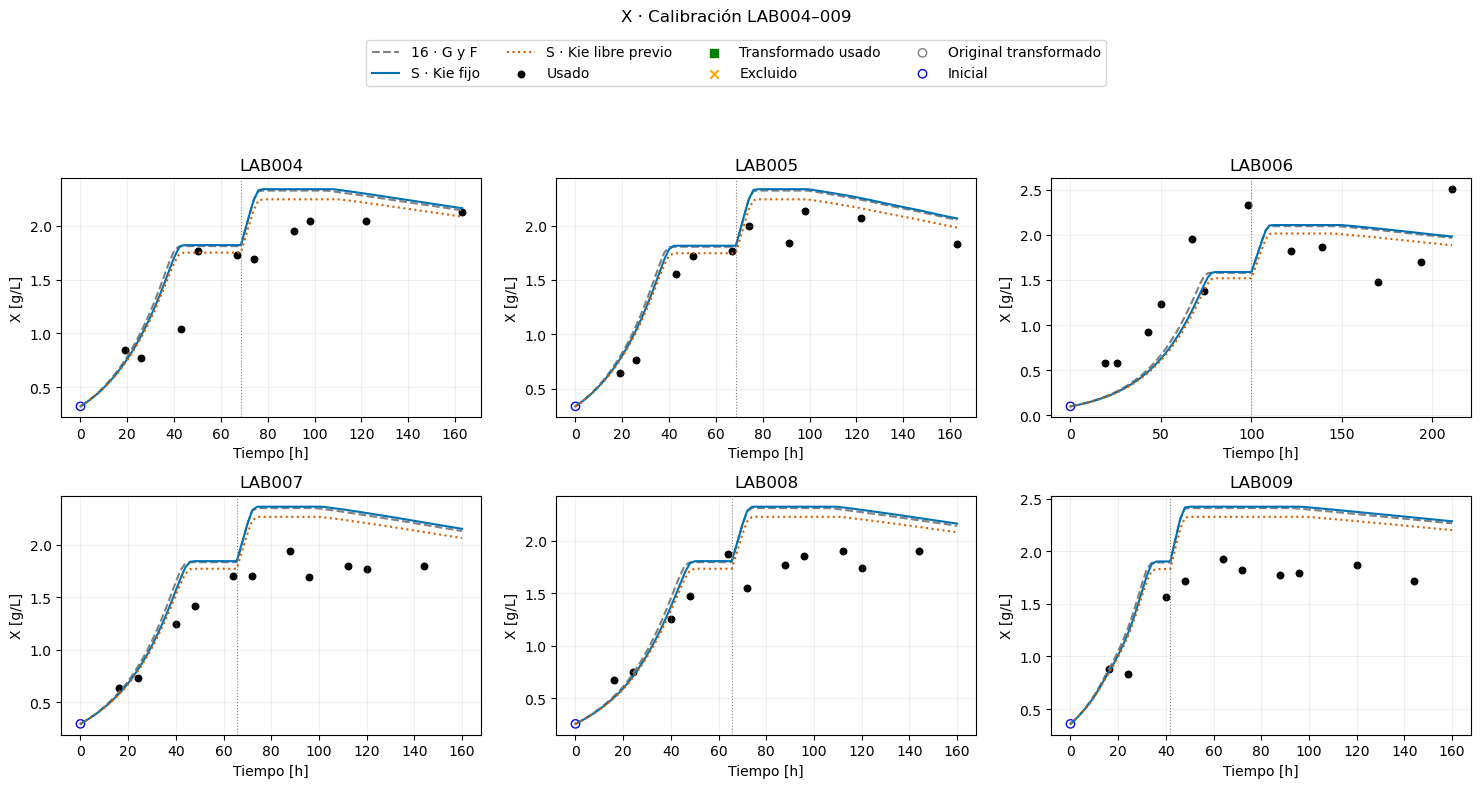

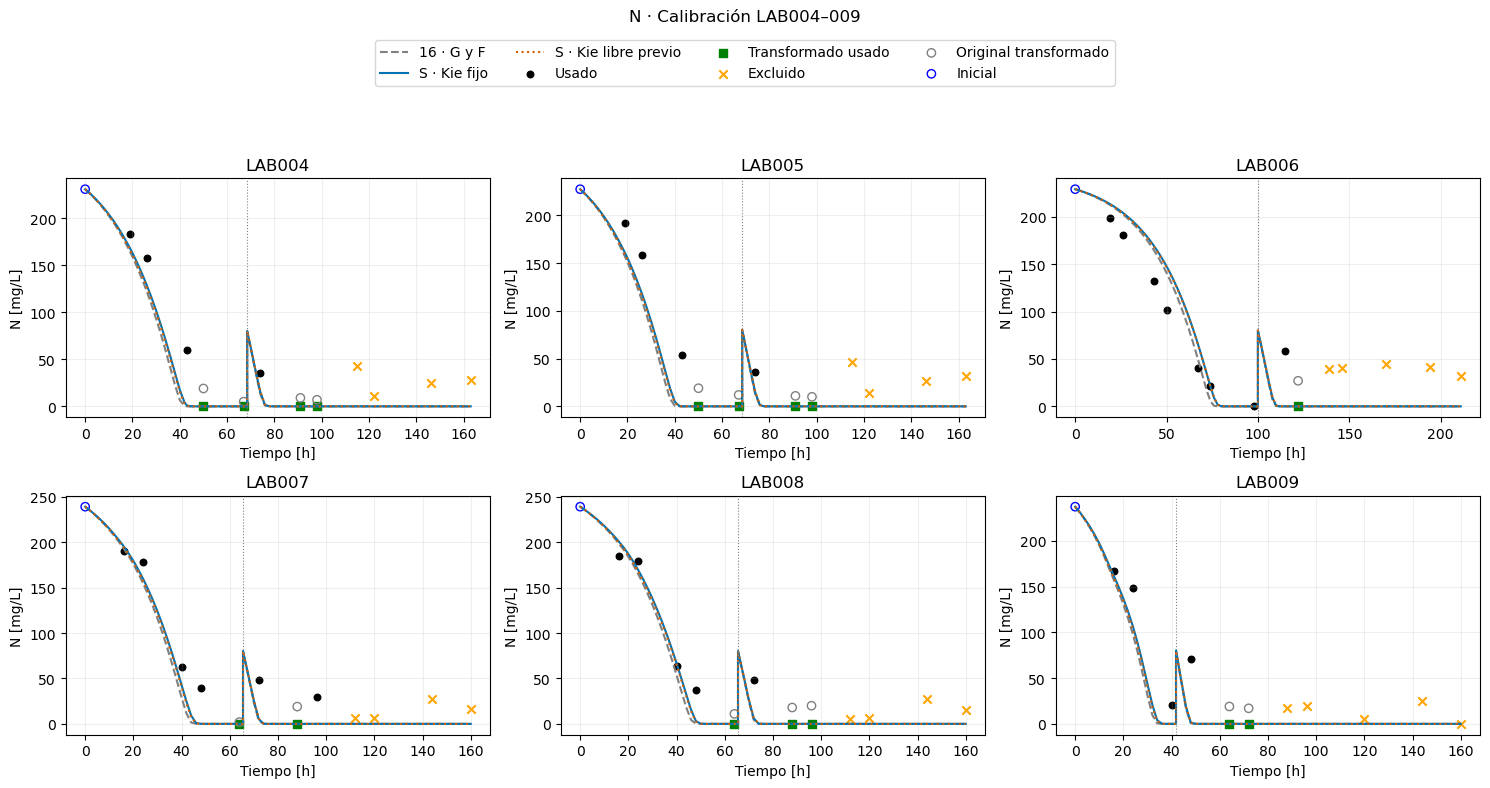

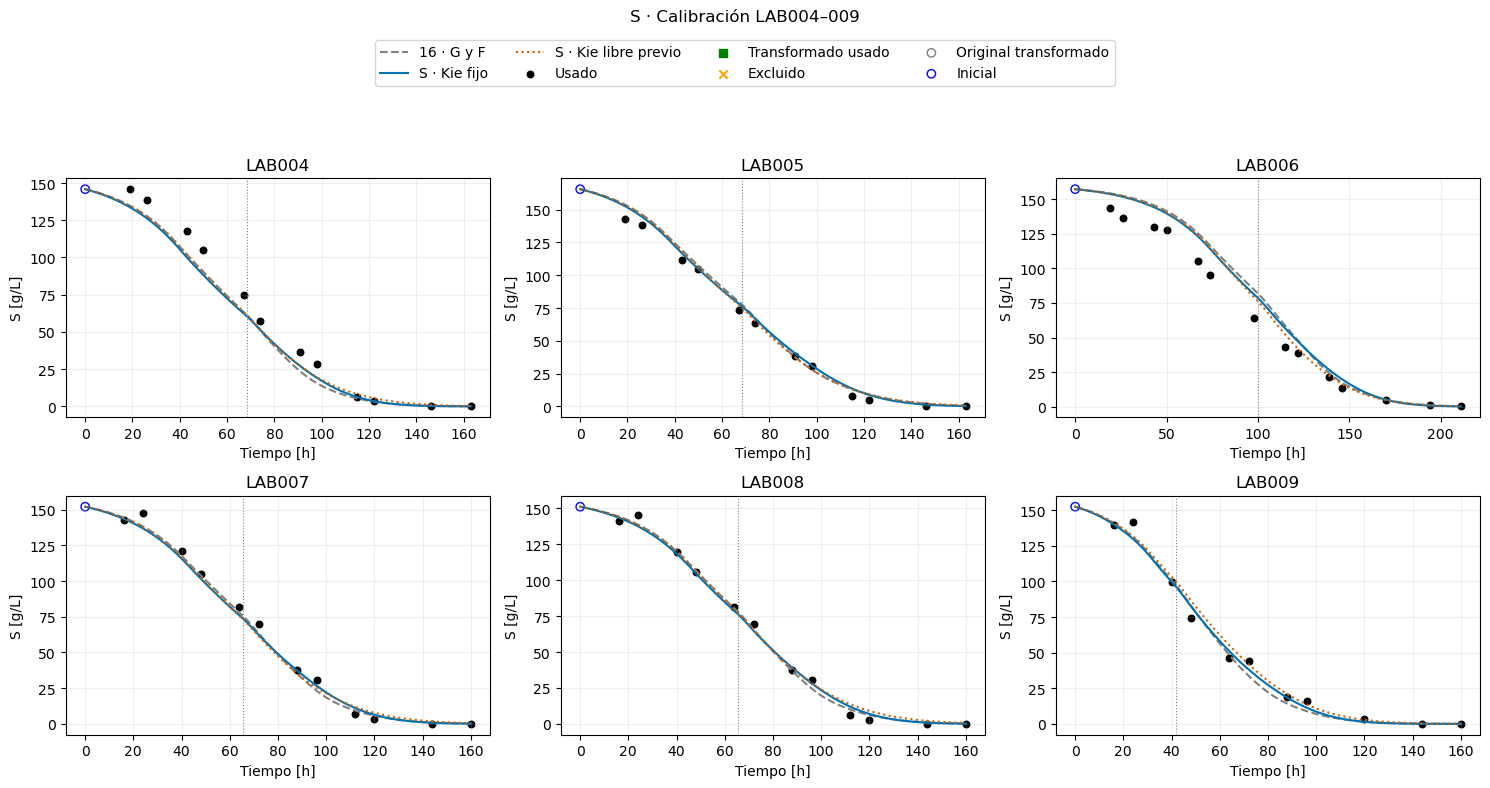

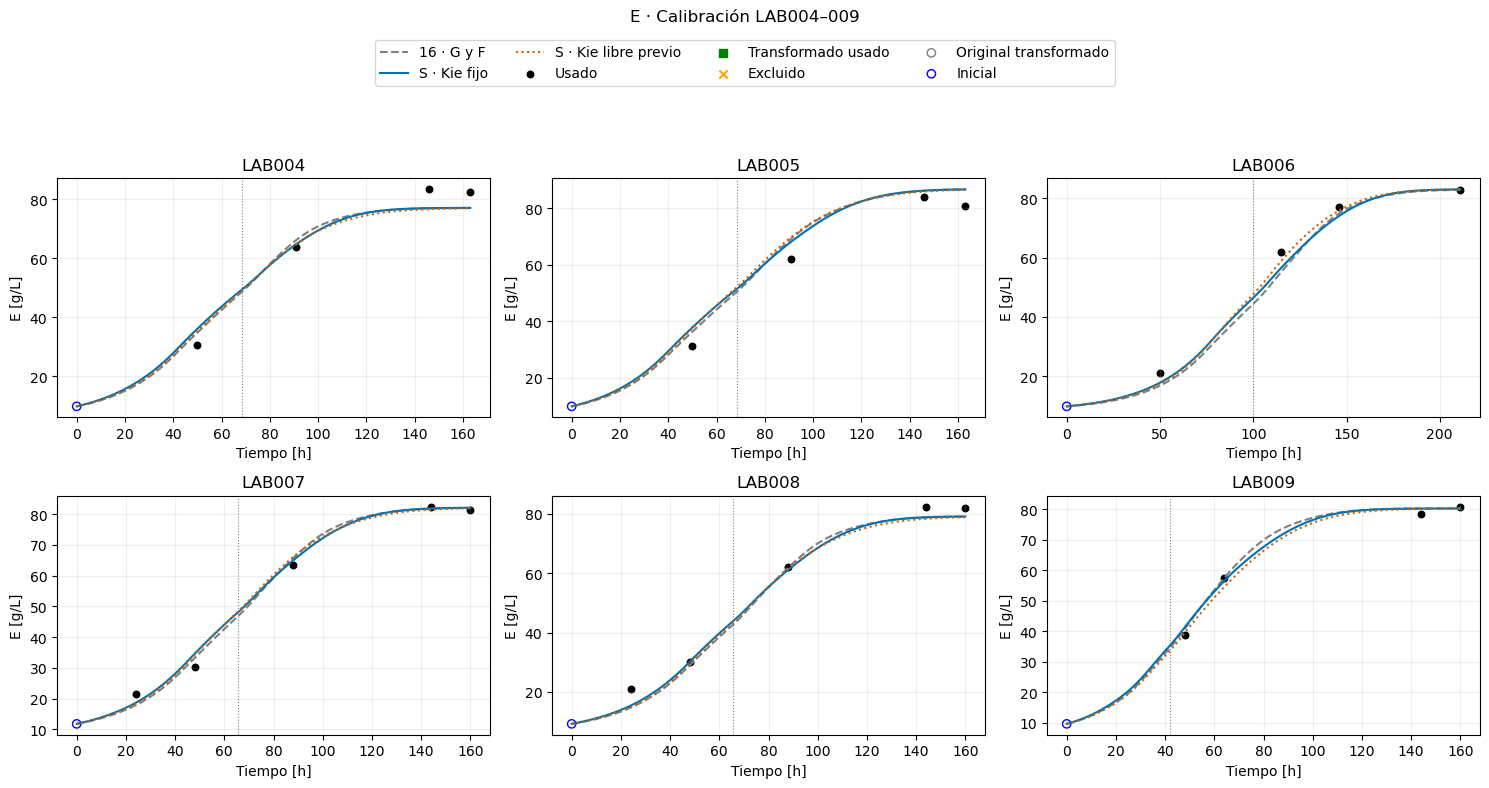

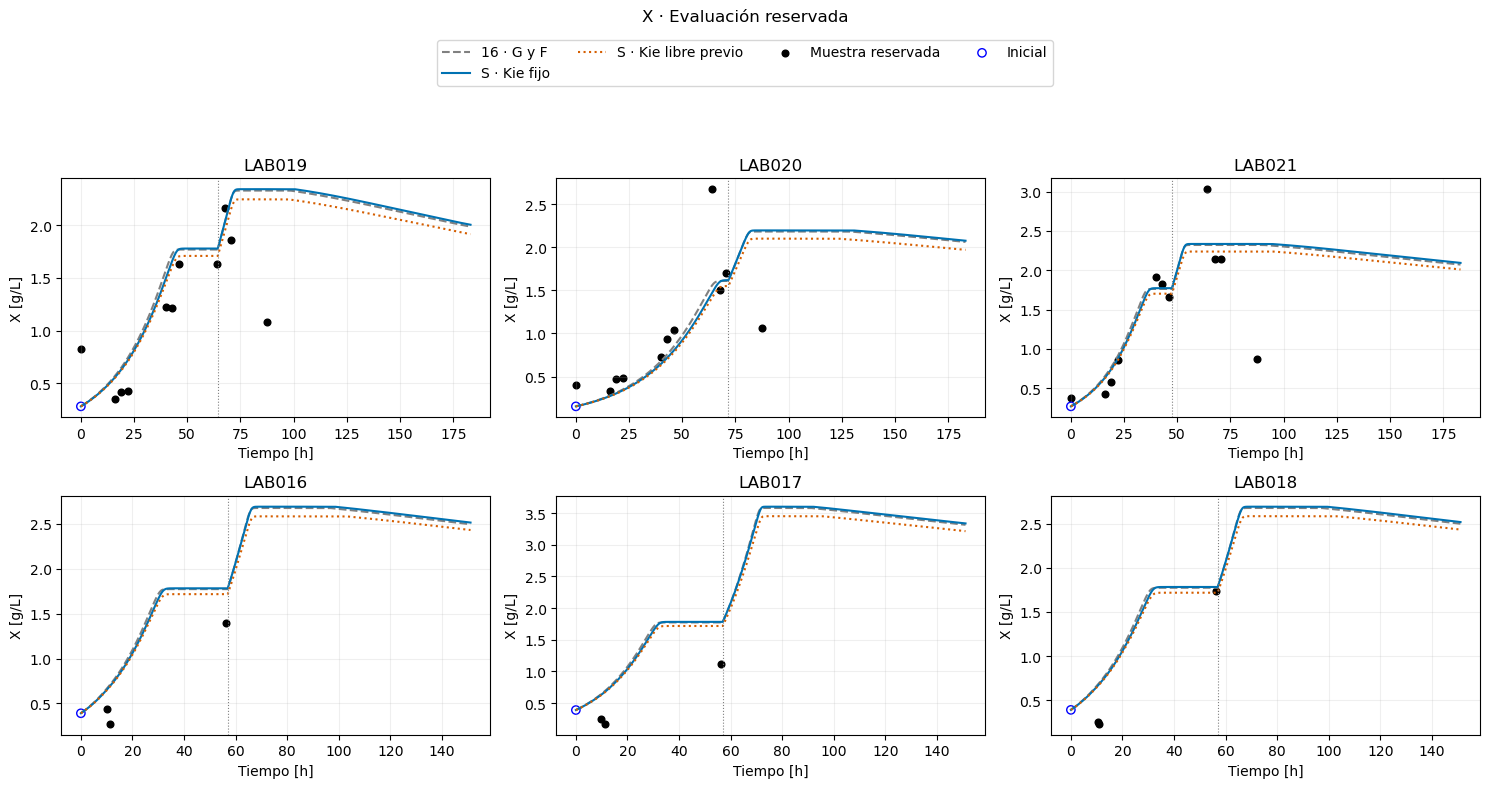

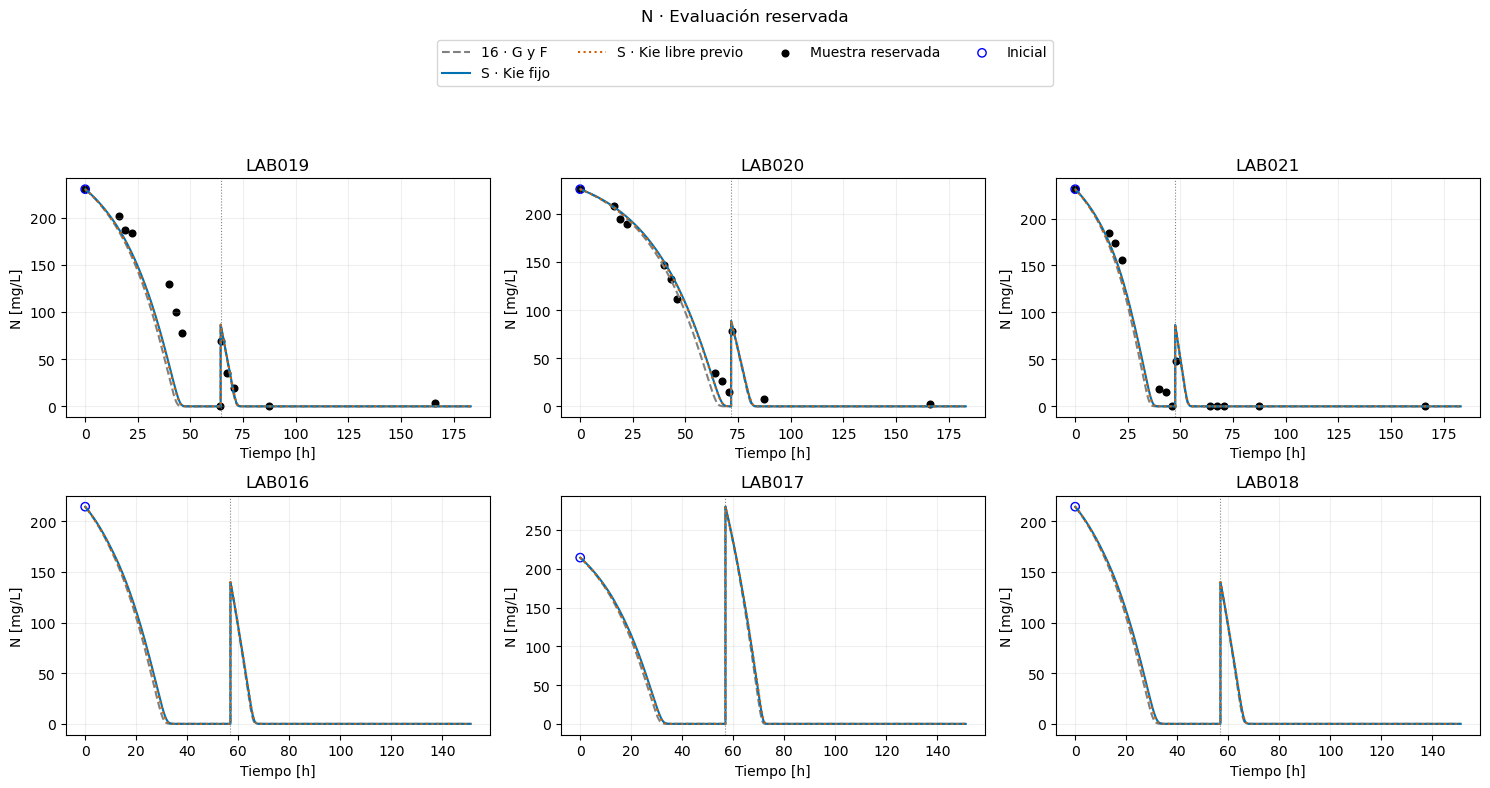

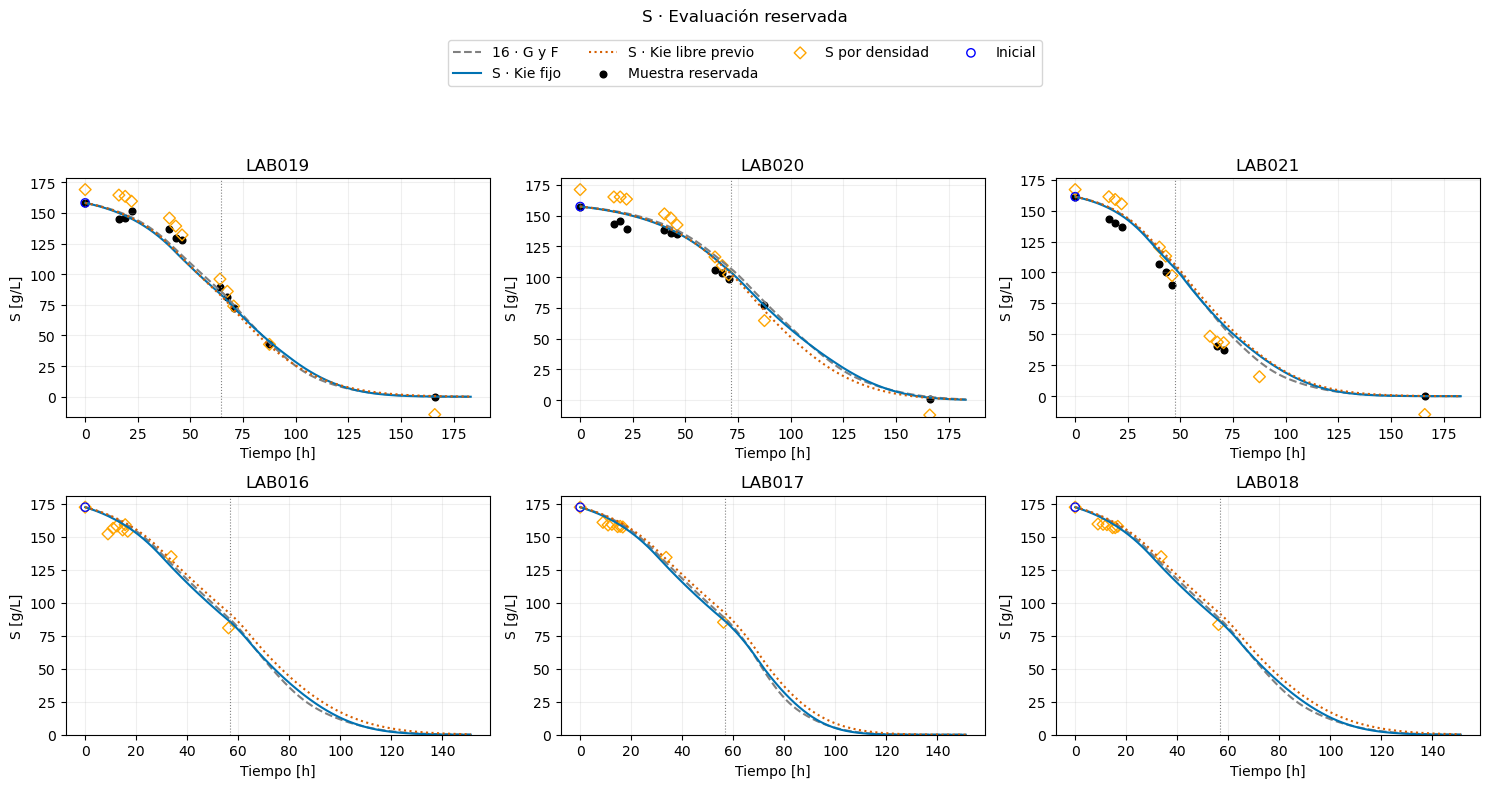

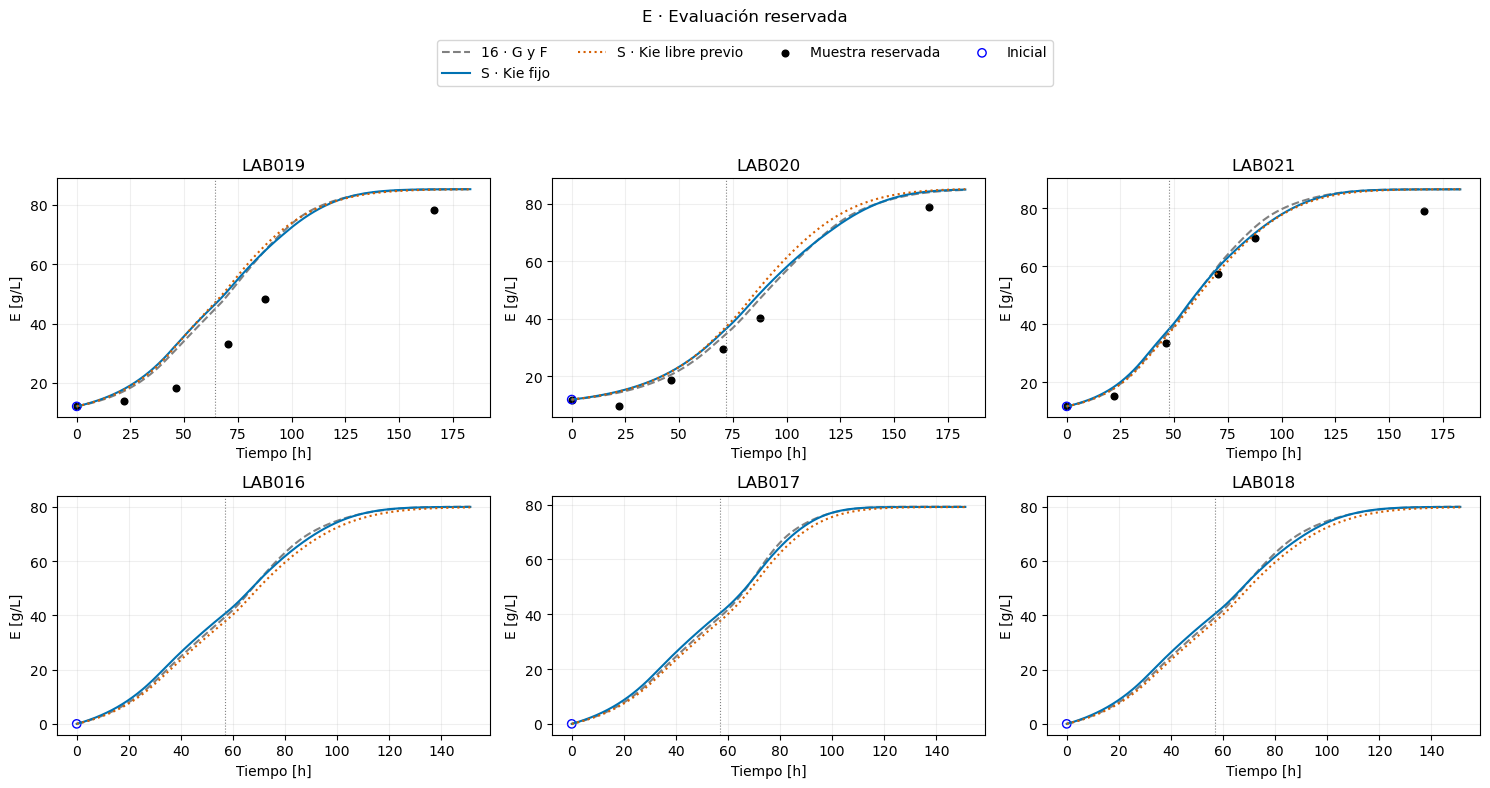

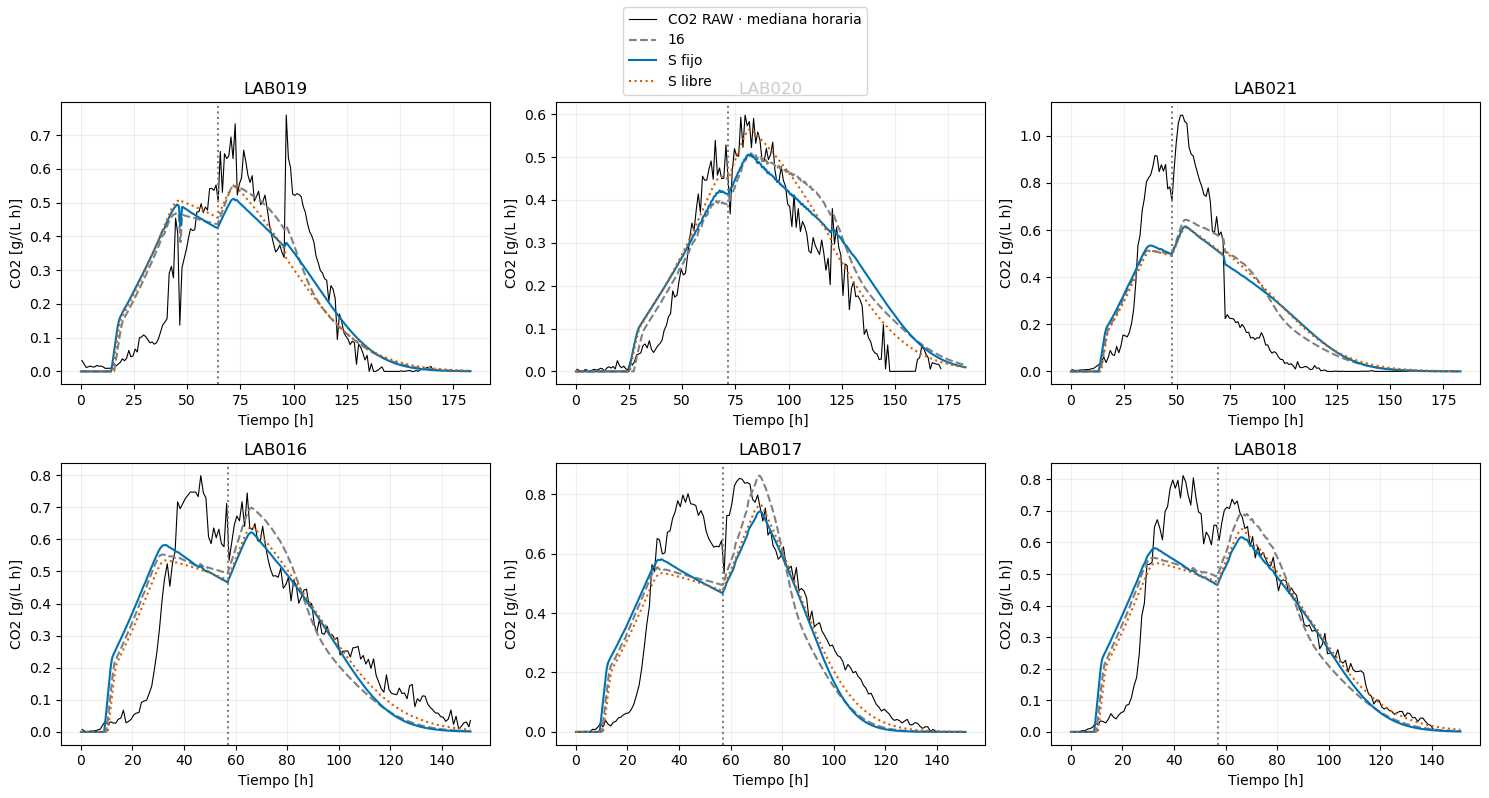

modelo                                     16     S fijo    S libre
rol            LAB    variable n                                   
Entrenamiento  LAB004 E        4     4.879543   5.028815   4.977355
                      N        8    26.638593  24.811488  25.272938
                      S        12   10.055109  10.236389   9.373491
                      X        10    0.353789   0.356708   0.302510
               LAB005 E        4     5.431243   5.485803   5.833423
                      N        8    29.091953  26.946898  27.536677
                      S        12    5.500948   4.562708   4.933043
                      X        10    0.245549   0.246304   0.186047
               LAB006 E        4     4.063489   3.414525   2.383501
                      N        9    27.906597  30.499204  30.114674
                      S        14   13.213141  11.932324  11.389147
                      X        12    0.471184   0.489876   0.496979
               LAB007 E        5     2.340730   2.442421   2.598175
                      N        8    27.336720  24.841771  25.122233
                      S        12    4.567574   5.030904   5.237112
                      X        11    0.430609   0.435457   0.359514
               LAB008 E        5     3.461338   3.200358   3.517730
                      N        8    21.489200  20.071840  20.047621
                      S        12    3.322800   3.617627   3.877070
                      X        11    0.397483   0.404257   0.336737
               LAB009 E        4     1.370620   1.628107   1.748737
                      N        6    36.453395  34.253782  34.763675
                      S        11    5.846610   5.109714   5.740490
                      X        10    0.518544   0.527360   0.447060
Evaluación gas LAB016 CO2      152   0.135560   0.140932   0.123653
               LAB017 CO2      141   0.138006   0.144107   0.129738
               LAB018 CO2      141   0.125537   0.132785   0.120924
               LAB019 CO2      166   0.112509   0.122624   0.127783
               LAB020 CO2      172   0.073342   0.072335   0.056864
               LAB021 CO2      166   0.186946   0.192509   0.198329
Reservado      LAB016 X        3     0.359155   0.354077   0.327789
               LAB017 X        3     0.536581   0.533142   0.503491
               LAB018 X        3     0.362133   0.351884   0.346247
               LAB019 E        5    12.423263  13.138972  13.765961
                      N        12   46.985655  42.366222  43.231868
                      S        11    6.533820   7.753826   7.530278
                      X        10    0.484605   0.473706   0.432214
               LAB020 E        5     4.811317   5.916497   6.717158
                      N        12   12.622841  10.815421  10.681888
                      S        11    8.121471   6.712841   6.692602
                      X        10    0.513404   0.538682   0.535273
               LAB021 E        5     4.343183   4.191579   3.761518
                      N        12   15.757195  14.420748  14.832582
                      S        9    13.583468  13.504035  15.810601
                      X        10    0.526470   0.527217   0.511232

,LAB,modelo,estado,primera_h_post_pulso,residual
0,LAB004,16,S,130.000000,0.063679
1,LAB004,16,N,76.000000,0.000000
2,LAB004,S fijo,S,130.000000,0.041412
3,LAB004,S fijo,N,78.000000,0.000000
4,LAB004,S libre,S,140.000000,0.292668
...,...,...,...,...,...
67,LAB018,16,N,66.666667,0.000000
68,LAB018,S fijo,S,121.083333,0.042103
69,LAB018,S fijo,N,67.083333,0.000000
70,LAB018,S libre,S,131.416667,0.339240


In [3]:

comparison=[]
def original_state(f,s):return f['GF' if s=='S' else s]
def draw_group(group,reference,reduced,reserved=False):
 for s in STATES:
  scale=1000 if s=='N' else 1;fig,axs=plt.subplots(2,3,figsize=(15,8));legend={}
  for ax,item in zip(axs.flat,group):
   b=batches[item] if reserved else item;lab=b.batch;a=with_jumps(reference[lab]);r=plotframe_s(reduced[lab]);u=plotframe_s((free_cores if reserved else free_train)[lab])
   ax.plot(a.index,original_state(a,s)*scale,c='gray',ls='--',label='16 · G y F');ax.plot(r.index,r[s]*scale,c='#0072B2',label='S · Kie fijo');ax.plot(u.index,u[s]*scale,c='#D55E00',ls=':',label='S · Kie libre previo')
   if not reserved:
    yy,sg,mask=targets(b,s);tt=b.time;raw=bylab[lab].observations[s] if s!='S' else bylab[lab].observations['G']+bylab[lab].observations['F'];available=np.isfinite(raw)&(tt>0);changed=mask&(raw!=yy);excluded=available&~mask
    ax.scatter(tt[mask&~changed],yy[mask&~changed]*scale,c='black',s=22,label='Usado');ax.scatter(tt[changed],yy[changed]*scale,c='green',marker='s',label='Transformado usado');ax.scatter(tt[excluded],raw[excluded]*scale,c='orange',marker='x',label='Excluido');ax.scatter(tt[changed],raw[changed]*scale,facecolors='none',edgecolors='gray',label='Original transformado')
   else:
    col='GF' if s=='S' else s
    if lab in TRAIN:
     z=chemical_observations(v.chem,lab,col);tt=z.t_h.to_numpy();yy=z[CHEMICAL_COLUMNS[col]].to_numpy()
    elif s=='X':
     z=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']);tt=z.t_h.to_numpy();yy=z.X_viable_g_l.to_numpy()
    else:tt=np.array([]);yy=np.array([])
    mask=np.isfinite(yy)&(tt>0)&(tt<=v.horizons[lab]);ax.scatter(tt,yy*scale,c='black',s=23,label='Muestra reservada')
    if s=='S':
     z=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l']);ax.scatter(z.t_h,2.5*(z.density_g_l-1000),marker='D',facecolors='none',edgecolors='orange',label='S por densidad');ax.set_ylim(bottom=min(0,float((2.5*(z.density_g_l-1000)).min())*1.15))
   for model,f,vals in [('16',a,original_state(a,s)),('S fijo',r,r[s]),('S libre',u,u[s])]:
    if mask.any():
     err=(np.interp(tt[mask],f.index,vals)-yy[mask])*scale;comparison.append(dict(LAB=lab,rol='Reservado' if reserved else 'Entrenamiento',variable=s,modelo=model,n=int(mask.sum()),RMSE=float(np.sqrt(np.mean(err**2))),sesgo=float(err.mean())))
   ax.scatter([0],[r[s].iloc[0]*scale],facecolors='none',edgecolors='blue',label='Inicial')
   for t,d in b.pulses['N']:ax.axvline(t,c='gray',ls=':',lw=.8)
   ax.set(title=lab,xlabel='Tiempo [h]',ylabel=s+(' [mg/L]' if s=='N' else ' [g/L]'));ax.grid(alpha=.2)
   for h,l in zip(*ax.get_legend_handles_labels()):legend[l]=h
  fig.suptitle(s+' · '+('Evaluación reservada' if reserved else 'Calibración LAB004–009'));fig.legend(legend.values(),legend.keys(),loc='upper center',bbox_to_anchor=(.5,.95),ncol=4);fig.tight_layout(rect=(0,0,1,.85));plt.show()
draw_group(treated,original_train,reduced_train)
draw_group(LABS,original_cores,reduced_cores,True)
fig,axs=plt.subplots(2,3,figsize=(15,8))
for ax,lab in zip(axs.flat,LABS):
 o=obs[lab];ax.plot(o.time_h,o.co2_raw_g_l_h,c='black',lw=.8,label='CO2 RAW · mediana horaria')
 for model,cur,color,style in [('16',original_gas,'gray','--'),('S fijo',reduced_gas,'#0072B2','-'),('S libre',free_gas,'#D55E00',':')]:
  f=cur[lab];ax.plot(f.index,f.qpred,c=color,ls=style,label=model);err=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h;comparison.append(dict(LAB=lab,rol='Evaluación gas',variable='CO2',modelo=model,n=len(o),RMSE=float(np.sqrt(np.mean(err**2))),sesgo=float(err.mean())))
 for t,d in batches[lab].pulses['N']:ax.axvline(t,c='gray',ls=':')
 ax.set(title=lab,xlabel='Tiempo [h]',ylabel='CO2 [g/(L h)]');ax.grid(alpha=.2)
fig.legend(*axs.flat[0].get_legend_handles_labels(),loc='upper center');fig.tight_layout(rect=(0,0,1,.92));plt.show()
metrics_s=pd.DataFrame(comparison);display(metrics_s.pivot(index=['rol','LAB','variable','n'],columns='modelo',values='RMSE'));print('MÉTRICAS_JSON',metrics_s.to_json(orient='records'))
# Agotamiento aproximado a umbral común, independiente de la regla de tratamiento YAN.
timing=[]
for lab,f in {**reduced_train,**reduced_cores}.items():
 a=original_train.get(lab,original_cores.get(lab))
 for model,frame in [('16',a),('S fijo',f),('S libre',free_train.get(lab,free_cores.get(lab)))]:
  for state,threshold in [('S',2.),('N',.001)]:
   values=original_state(frame,state) if model=='16' else frame[state];lastpulse=max(t for t,d in (bylab.get(lab,batches.get(lab))).pulses['N']);ids=np.flatnonzero((frame.index>lastpulse)&(values<=threshold));timing.append(dict(LAB=lab,modelo=model,estado=state,primera_h_post_pulso=float(frame.index[ids[0]]) if len(ids) else np.nan,residual=float(values.iloc[-1])))
display(pd.DataFrame(timing))
assert ps['Kie0']==original_theta['Kie0']
assert theta==original_theta and theta['Kd0']==.00044 and np.isclose(theta['Kn0']*KN_THERMAL_FACTOR,.01)
assert KLA==.07467887635557982 and GAIN==.635238911849421
for lab,f in reduced_cores.items():
 for t,bef,aft in f.attrs['jumps']:assert np.array_equal(bef[[0,2,3]],aft[[0,2,3]])
for p,h in hashes.items():assert hashlib.sha256(p.read_bytes()).hexdigest()==h,str(p)
print('Datos, configuraciones y notebooks previos intactos. Kn, Kd0, kLa y ganancia fijos. Sin ajuste sobre ensayos reservados.')


## Resultado Kie0 fijo
Ambos inicios convergen (MSE3.351947 y3.351874); referencia Kie libre MSE3.243679. Aumento de coste ponderado3.34%. Sin rechazos numéricos. Nuevo ajuste: mu0=.0908505882, betaS0=.8189664539, Ks0=23.04656457, Kie0=96.26516563 fijo, Yxn=6.49733161, Yes=.4893180893. Ninguno de los cinco libres queda cerca de sus cotas según el criterio tabulado.
Ks0 disminuye55.5% al restablecer la inhibición por etanol del16: evidencia compatible con compensación Ks/Kie, sin demostrar que toda la compensación provenga de eliminar G/F.
Frente a Kie libre: CO2 mejora019/021, empeora020/016–018. RMSE medio S reservado mejora10.0112→9.3236g/L; E8.0815→7.7490g/L; N22.9154→22.5341mg/L; X empeora.44271→.46312g/L. Estos son promedios de RMSE por ensayo con el soporte documentado; no equivalen a un RMSE global ni a validación ciega.
Referencia16 media S9.4129g/L, E7.1926g/L, N25.1219mg/L y X.46372g/L. Nueve figuras, mismos puntos para los tres modelos, iniciales fuera de puntuación, tablas de convergencia/cotas/sensibilidad. Balance del integrador gas y hashes previos comprobados.
